# Project 3: Unsupervised Learning (Customer Segmentation)

**Goal:** Use distance-based algorithms to discover hidden mathematical groupings in unlabeled retail data.

**Key requirements**
1. Apply **Principal Component Analysis (PCA)** to reduce 20+ columns of data into 2 or 3 dimensions.
2. Use the **Elbow Method** and **Silhouette Score** to mathematically prove the optimal number of K-Means clusters.
3. Translate the resulting clusters into actionable business **Personas**.

**Key skills:** Dimensionality reduction (PCA), K-Means clustering, distance metrics, business intelligence translation.

## 1. Load the data

In [1]:
import sys
print(sys.executable)

c:\Users\AR COMPUTERS\AppData\Local\Programs\Python\Python314\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

df = pd.read_csv("Dataset for Data Analytics - Sheet1.csv")
print(df.shape)
df.head()

(1200, 14)


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,1/4/2023,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,8/23/2024,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2/27/2024,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,10/15/2023,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,5/8/2025,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [3]:
df.info()
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nUnique customers:", df["CustomerID"].nunique())

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   str    
 1   Date             1200 non-null   str    
 2   CustomerID       1200 non-null   str    
 3   Product          1200 non-null   str    
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   str    
 7   PaymentMethod    1200 non-null   str    
 8   OrderStatus      1200 non-null   str    
 9   TrackingNumber   1200 non-null   str    
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       891 non-null    str    
 12  ReferralSource   1200 non-null   str    
 13  TotalPrice       1200 non-null   float64
dtypes: float64(2), int64(2), str(10)
memory usage: 131.4 KB

Missing values:
 CouponCode    309
dtype: int64

Unique customers: 1189


## 2. Prepare the feature matrix (20+ columns)

- `CouponCode` is missing when no coupon was used, so we fill it with `"None"`.
- Identifier / free-text columns (`OrderID`, `TrackingNumber`, `ShippingAddress`, `Date`) carry no behavioural signal for distance-based clustering, so they are dropped.
- Categorical columns are one-hot encoded.
- Data is aggregated to **one row per customer** (`CustomerID`), since we are segmenting customers, not orders.

In [4]:
df["CouponCode"] = df["CouponCode"].fillna("None")

numeric_cols = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]
categorical_cols = ["Product", "PaymentMethod", "OrderStatus", "CouponCode", "ReferralSource"]

dummies = pd.get_dummies(df[categorical_cols]).astype(int)
order_level = pd.concat([df[["CustomerID"] + numeric_cols], dummies], axis=1)

# Aggregate to customer level
agg_rules = {"Quantity": "sum", "UnitPrice": "mean", "ItemsInCart": "mean", "TotalPrice": "sum"}
agg_rules.update({c: "sum" for c in dummies.columns})
customers = order_level.groupby("CustomerID").agg(agg_rules)

print("Customer feature matrix:", customers.shape)
print("Number of columns used for PCA:", customers.shape[1])
customers.head()

Customer feature matrix: (1189, 30)
Number of columns used for PCA: 30


,Quantity,UnitPrice,ItemsInCart,TotalPrice,Product_Chair,Product_Desk,Product_Laptop,Product_Monitor,Product_Phone,Product_Printer,...,OrderStatus_Shipped,CouponCode_FREESHIP,CouponCode_None,CouponCode_SAVE10,CouponCode_WINTER15,ReferralSource_Email,ReferralSource_Facebook,ReferralSource_Google,ReferralSource_Instagram,ReferralSource_Referral
CustomerID,,,,,,,,,,,,,,,,,,,,,
C10002,3,490.01,4.0,1470.03,0,0,0,0,0,1,...,0,0,0,1,0,0,1,0,0,0
C10054,2,76.74,7.0,153.48,0,0,1,0,0,0,...,0,0,0,1,0,0,0,0,1,0
C10126,2,674.90,4.0,1349.80,0,0,0,1,0,0,...,1,0,0,1,0,0,1,0,0,0
C10154,4,325.76,8.0,1303.04,0,1,0,0,0,0,...,1,0,0,0,1,1,0,0,0,0
C10211,5,127.18,10.0,635.90,0,1,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0


## 3. Scale the features
K-Means and PCA are **distance / variance based**, so features measured in large units (e.g. `TotalPrice`) would dominate the Euclidean distance. Standardising every column to mean 0 and standard deviation 1 gives each feature equal weight.

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)
print("Mean ≈", X_scaled.mean().round(3), "| Std ≈", X_scaled.std().round(3))

Mean ≈ 0.0 | Std ≈ 1.0


## 4. Principal Component Analysis (PCA): 30 columns → 2 dimensions

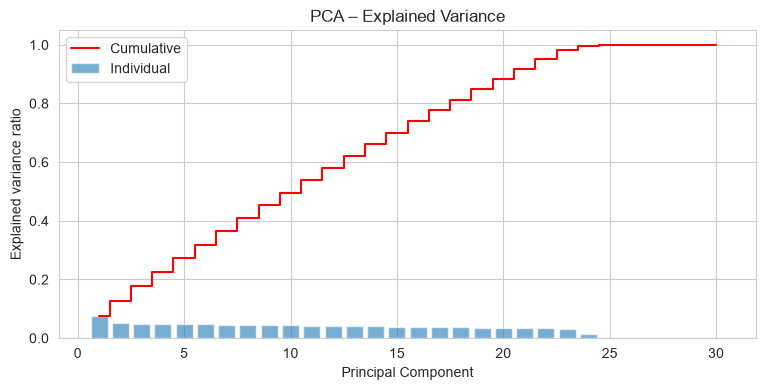

In [6]:
# Variance explained by all components
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(9, 4))
plt.bar(range(1, len(cum_var) + 1), pca_full.explained_variance_ratio_, alpha=0.6, label="Individual")
plt.step(range(1, len(cum_var) + 1), cum_var, where="mid", color="red", label="Cumulative")
plt.xlabel("Principal Component"); plt.ylabel("Explained variance ratio")
plt.title("PCA – Explained Variance"); plt.legend(); plt.show()

In [7]:
# Compare 2-D vs 3-D reduction
for n in [2, 3]:
    p = PCA(n_components=n, random_state=RANDOM_STATE).fit(X_scaled)
    Z = p.transform(X_scaled)
    sils = [silhouette_score(Z, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)) for k in range(2, 11)]
    print(f"{n}-D PCA | variance retained = {p.explained_variance_ratio_.sum():.2%} | best silhouette (k=2..10) = {max(sils):.3f}")

2-D PCA | variance retained = 12.65% | best silhouette (k=2..10) = 0.376
3-D PCA | variance retained = 17.63% | best silhouette (k=2..10) = 0.275


The 2-D projection produces clearly better-separated clusters (higher silhouette) than 3-D, so we keep **2 principal components**.

> Note: the retained variance is modest because most of the 30 columns are one-hot flags that are nearly independent of each other. PCA still captures the strongest structure: the spending variables.

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance per component:", pca.explained_variance_ratio_.round(4))

loadings = pd.DataFrame(pca.components_.T, index=customers.columns, columns=["PC1", "PC2"])
print("\nTop features driving PC1:"); print(loadings["PC1"].abs().sort_values(ascending=False).head(5))
print("\nTop features driving PC2:"); print(loadings["PC2"].abs().sort_values(ascending=False).head(5))

Explained variance per component: [0.0763 0.0501]

Top features driving PC1:
TotalPrice       0.595273
Quantity         0.539337
ItemsInCart      0.458336
UnitPrice        0.332571
Product_Phone    0.080877
Name: PC1, dtype: float64

Top features driving PC2:
UnitPrice                   0.350941
ReferralSource_Instagram    0.326458
ReferralSource_Referral     0.314014
OrderStatus_Pending         0.298203
Product_Phone               0.289250
Name: PC2, dtype: float64


- **PC1 = Spending / basket size**: driven by `TotalPrice`, `Quantity`, `ItemsInCart`, `UnitPrice`.
- **PC2 = Channel & product preference**: separates Referral / Gift Card / Phone / Shipped customers from Instagram / Cash / Pending / Chair customers.

## 5. Finding the optimal K
### 5a. Elbow Method (Within-Cluster Sum of Squares)

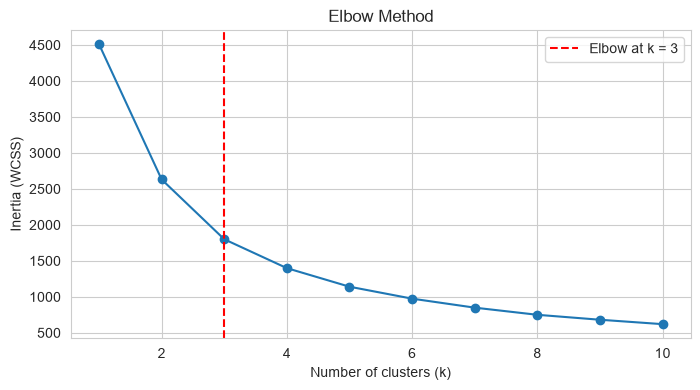

 k  Inertia  Drop from previous
 1   4511.4                 NaN
 2   2631.5              1879.9
 3   1800.0               831.4
 4   1398.5               401.5
 5   1140.5               258.0
 6    974.4               166.1
 7    849.4               125.0
 8    750.1                99.3
 9    681.4                68.7
10    620.1                61.3

Elbow (max-distance method) → k = 3


In [9]:
K_range = range(1, 11)
inertia = []
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
    inertia.append(km.inertia_)

# Mathematical elbow: point with maximum distance from the line joining first and last points
x = np.array(K_range); y = np.array(inertia)
x_n = (x - x.min()) / (x.max() - x.min()); y_n = (y - y.min()) / (y.max() - y.min())
distances = np.abs(y_n - (1 - x_n)) / np.sqrt(2)
elbow_k = int(x[np.argmax(distances)])

plt.figure(figsize=(8, 4))
plt.plot(x, y, "o-")
plt.axvline(elbow_k, color="red", linestyle="--", label=f"Elbow at k = {elbow_k}")
plt.xlabel("Number of clusters (k)"); plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method"); plt.legend(); plt.show()

print(pd.DataFrame({"k": x, "Inertia": np.round(y, 1),
                    "Drop from previous": np.round(np.r_[np.nan, -np.diff(y)], 1)}).to_string(index=False))
print("\nElbow (max-distance method) → k =", elbow_k)

### 5b. Silhouette Score

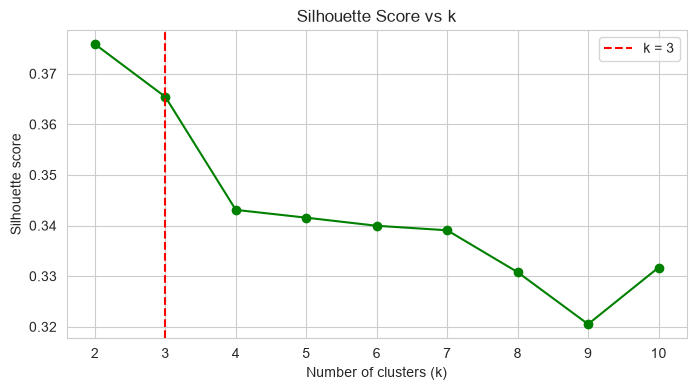

 k  Silhouette
 2      0.3758
 3      0.3654
 4      0.3431
 5      0.3416
 6      0.3400
 7      0.3391
 8      0.3308
 9      0.3205
10      0.3317


In [10]:
sil_range = range(2, 11)
sil_scores = []
for k in sil_range:
    labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_pca)
    sil_scores.append(silhouette_score(X_pca, labels))

plt.figure(figsize=(8, 4))
plt.plot(list(sil_range), sil_scores, "o-", color="green")
plt.axvline(elbow_k, color="red", linestyle="--", label=f"k = {elbow_k}")
plt.xlabel("Number of clusters (k)"); plt.ylabel("Silhouette score")
plt.title("Silhouette Score vs k"); plt.legend(); plt.show()

print(pd.DataFrame({"k": list(sil_range), "Silhouette": np.round(sil_scores, 4)}).to_string(index=False))

### 5c. Decision: **k = 3**
- **Elbow Method:** the largest bend in the inertia curve is at **k = 3**. Going from 2 → 3 clusters cuts inertia by ~830, but 3 → 4 only cuts it by ~400, so extra clusters give diminishing returns.
- **Silhouette Score:** k = 3 scores **≈ 0.365**, the **highest of any k ≥ 3** and only ~0.01 below k = 2. k = 2 just splits customers into "high" vs "low" spenders, which is too coarse to be useful for marketing.

Both methods agree on **k = 3** as the best balance of compact, well-separated and useful clusters.

In [11]:
OPTIMAL_K = 3
kmeans = KMeans(n_clusters=OPTIMAL_K, n_init=10, random_state=RANDOM_STATE)
customers["Cluster"] = kmeans.fit_predict(X_pca)
print("Silhouette score (k=3):", round(silhouette_score(X_pca, customers["Cluster"]), 4))
customers["Cluster"].value_counts().sort_index()

Silhouette score (k=3): 0.3654


Cluster
0    413
1    403
2    373
Name: count, dtype: int64

## 6. Visualise the clusters in PCA space

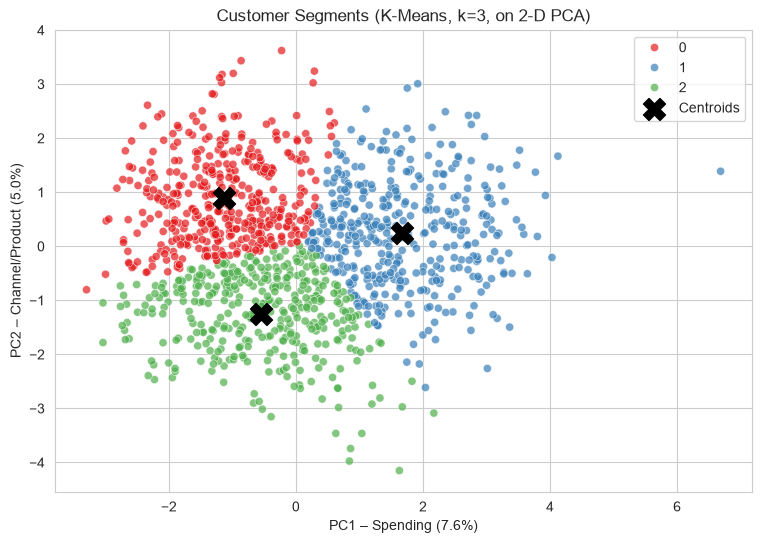

In [12]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=customers["Cluster"], palette="Set1", s=35, alpha=0.7)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="black", marker="X", s=250, label="Centroids")
plt.xlabel(f"PC1 – Spending ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 – Channel/Product ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("Customer Segments (K-Means, k=3, on 2-D PCA)"); plt.legend(); plt.show()

## 7. Cluster profiling

In [13]:
profile = customers.groupby("Cluster").mean().T
profile.loc["Customers"] = customers["Cluster"].value_counts().sort_index()
pd.set_option("display.float_format", "{:.2f}".format)
profile

Cluster,0,1,2
Quantity,1.88,4.17,2.88
UnitPrice,352.81,482.37,225.45
ItemsInCart,3.93,7.06,5.51
TotalPrice,605.51,1965.61,596.63
Product_Chair,0.07,0.18,0.21
Product_Desk,0.12,0.13,0.18
Product_Laptop,0.13,0.15,0.15
Product_Monitor,0.11,0.15,0.16
Product_Phone,0.25,0.10,0.03
Product_Printer,0.18,0.16,0.11


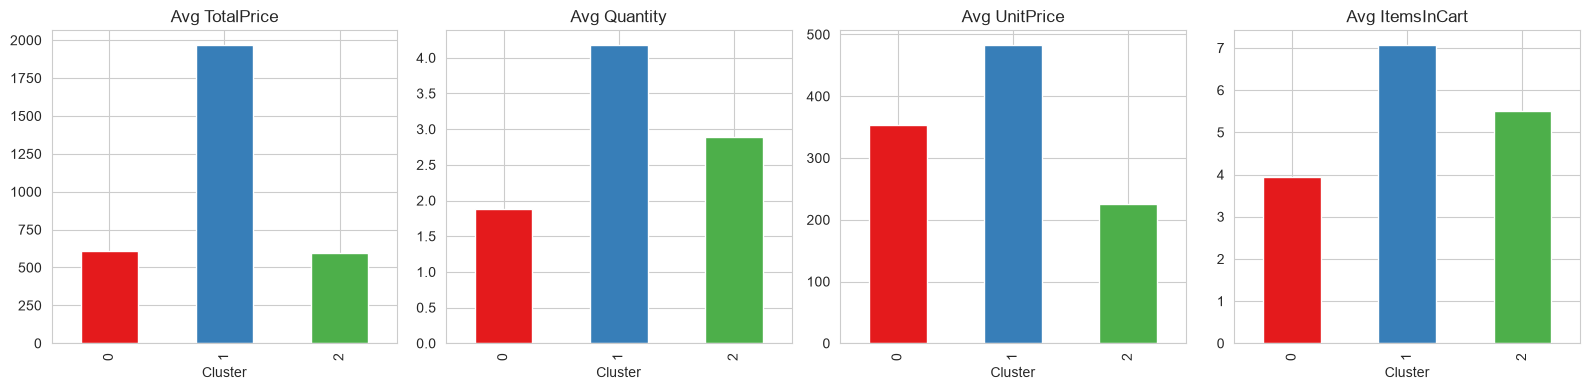

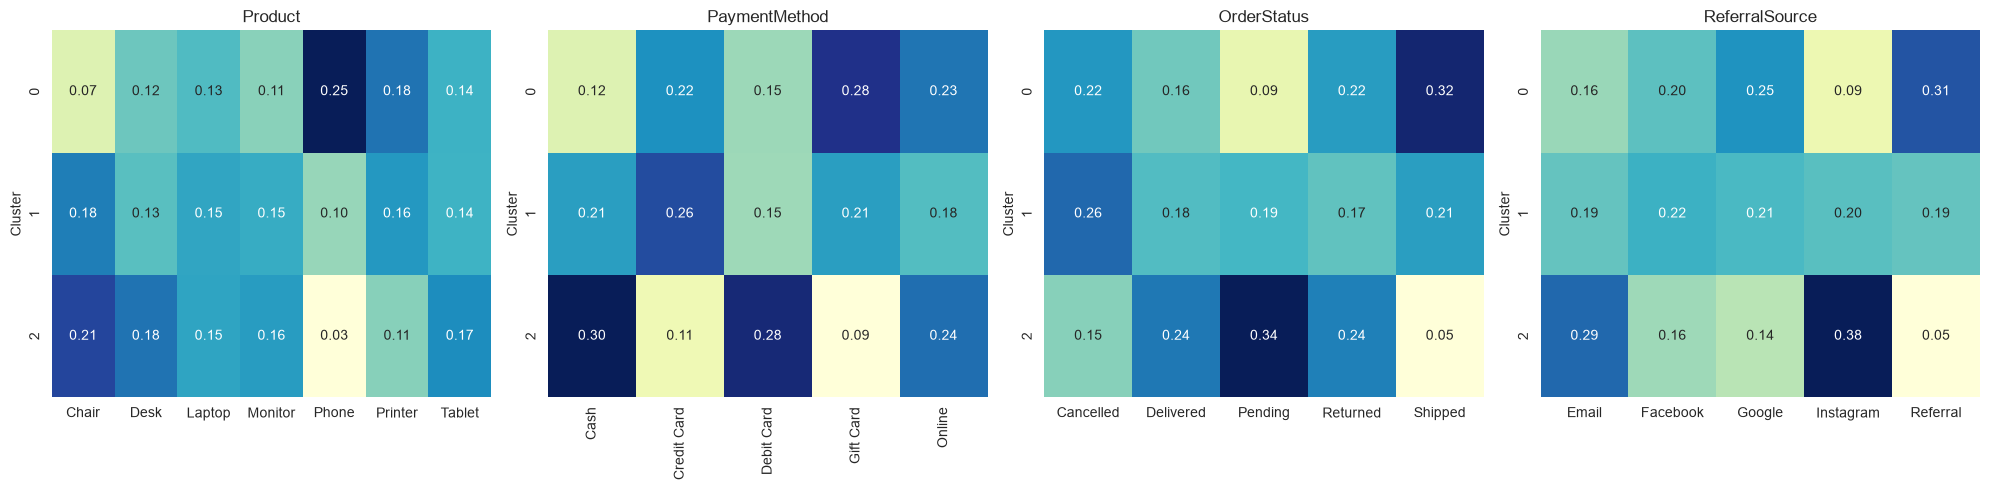

In [14]:
# Spending profile
spend = customers.groupby("Cluster")[["TotalPrice", "Quantity", "UnitPrice", "ItemsInCart"]].mean()
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, spend.columns):
    spend[col].plot(kind="bar", ax=ax, color=sns.color_palette("Set1", OPTIMAL_K))
    ax.set_title(f"Avg {col}"); ax.set_xlabel("Cluster")
plt.tight_layout(); plt.show()

# Behavioural profile: share of each category per cluster
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, prefix in zip(axes, ["Product", "PaymentMethod", "OrderStatus", "ReferralSource"]):
    cols = [c for c in customers.columns if c.startswith(prefix + "_")]
    share = customers.groupby("Cluster")[cols].mean()
    share.columns = [c.replace(prefix + "_", "") for c in cols]
    sns.heatmap(share, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax, cbar=False)
    ax.set_title(prefix)
plt.tight_layout(); plt.show()

## 8. Business personas

In [15]:
summary = customers.groupby("Cluster").agg(
    Customers=("TotalPrice", "size"),
    Avg_Spend=("TotalPrice", "mean"),
    Avg_Quantity=("Quantity", "mean"),
    Avg_UnitPrice=("UnitPrice", "mean"),
    Avg_ItemsInCart=("ItemsInCart", "mean"),
)
summary["Revenue_Share_%"] = customers.groupby("Cluster")["TotalPrice"].sum() / customers["TotalPrice"].sum() * 100

def top_category(prefix):
    cols = [c for c in customers.columns if c.startswith(prefix + "_")]
    return customers.groupby("Cluster")[cols].mean().idxmax(axis=1).str.replace(prefix + "_", "")

for p in ["Product", "PaymentMethod", "OrderStatus", "ReferralSource", "CouponCode"]:
    summary["Top_" + p] = top_category(p)
summary.round(2)

,Customers,Avg_Spend,Avg_Quantity,Avg_UnitPrice,Avg_ItemsInCart,Revenue_Share_%,Top_Product,Top_PaymentMethod,Top_OrderStatus,Top_ReferralSource,Top_CouponCode
Cluster,,,,,,,,,,,
0,413,605.51,1.88,352.81,3.93,19.77,Phone,Gift Card,Shipped,Referral,FREESHIP
1,403,1965.61,4.17,482.37,7.06,62.63,Chair,Credit Card,Cancelled,Facebook,FREESHIP
2,373,596.63,2.88,225.45,5.51,17.60,Chair,Cash,Pending,Instagram,WINTER15


In [16]:
# Name each cluster automatically by its spending + channel profile
s = summary
high_value = s["Avg_Spend"].idxmax()
remaining = s.drop(high_value)
budget = remaining["Avg_UnitPrice"].idxmin()
loyal = [c for c in s.index if c not in (high_value, budget)][0]

persona_names = {
    high_value: "Premium Bulk Buyers",
    loyal:      "Referral-Driven Tech Shoppers",
    budget:     "Budget Social-Media Shoppers",
}
customers["Persona"] = customers["Cluster"].map(persona_names)
summary.insert(0, "Persona", summary.index.map(persona_names))
summary[["Persona", "Customers", "Avg_Spend", "Revenue_Share_%", "Avg_Quantity", "Avg_UnitPrice"]].round(1)

,Persona,Customers,Avg_Spend,Revenue_Share_%,Avg_Quantity,Avg_UnitPrice
Cluster,,,,,,
0,Referral-Driven Tech Shoppers,413,605.50,19.80,1.90,352.80
1,Premium Bulk Buyers,403,1965.60,62.60,4.20,482.40
2,Budget Social-Media Shoppers,373,596.60,17.60,2.90,225.40


### Persona descriptions & recommended actions

| Persona | Who they are (data evidence) | Recommended business action |
|---|---|---|
| **Premium Bulk Buyers** | Highest spend (~$1,970 per customer, roughly 3× the other groups), buy ~4 units of higher-priced items (~$480), biggest carts (~7 items). Generate **~63% of total revenue** while being only about a third of customers. Mostly pay by Credit Card. | **Retain & upsell:** VIP/loyalty tier, volume discounts, priority shipping, early access to premium products (laptops, monitors). Watch their cancellation rate closely. |
| **Referral-Driven Tech Shoppers** | Small baskets (~2 units) of mid-priced items (~$350). Over-index on **Phones & Printers**, **Gift Card** payments, **Referral & Google** traffic, and use **FREESHIP / SAVE10** coupons. Orders are often already *Shipped*. | **Grow basket size:** referral rewards, "refer-a-friend" credits, accessory bundles with phones, free-shipping thresholds to push a 2nd item into the cart. |
| **Budget Social-Media Shoppers** | Lowest unit price (~$225). Mostly reached via **Instagram & Email**, prefer **Cash / Debit Card**, buy **Chairs / Desks**, often order *without a coupon* or with WINTER15, and have the **highest share of Pending orders**. | **Convert & speed up:** targeted Instagram/email promos, seasonal discounts, easier digital payment options to cut pending orders, and furniture bundles to raise order value. |

## 9. Conclusion
- **PCA** reduced **30 features** (4 numeric + 26 one-hot) to **2 principal components**: *Spending* (PC1) and *Channel/Product preference* (PC2).
- The **Elbow Method** (max-distance elbow at k = 3) and the **Silhouette Score** (≈ 0.365, best for k ≥ 3) together show that **k = 3** is the best number of K-Means clusters.
- The three clusters turn into clear, actionable personas: **Premium Bulk Buyers**, **Referral-Driven Tech Shoppers** and **Budget Social-Media Shoppers**, each with its own marketing strategy.